# Can a few axes summarize Asteron RNA?

We have seen how six hidden processes generated the experiment. Now we take the analyst's position: **we fit a six-component PCA to Asteron's RNA measurements only**, using 80 inhabitants × 90 features. Protein and Borealis do not enter this fit, and the true scores and weights are hidden until the final diagnostic.

As we work through the cells together, keep three objects distinct: the measured table, the inhabitants' coordinates on the fitted axes, and the genes' contributions to those axes. **Predict:** should PC1 primarily reflect disease, metabolism or technical batch? What can a two-dimensional sample map leave out?

### Load observations, keeping truth hidden

As in notebook 01, the path setup imports our local helper module. It also supplies `np`, `pd`, `plt` and `SPEC` used later in the code. `load_experiment()` reads the canonical AnnData observations; it does not regenerate them or use the teacher arrays. We will select Asteron RNA in the next step.

In [2]:
from pathlib import Path
import sys, time
HERE = Path.cwd() if Path('course_utils.py').exists() else Path.cwd() / 'notebooks'
sys.path.insert(0, str(HERE))
from course_utils import *
from IPython.display import display
from sklearn.decomposition import PCA
# Observations only. Ground truth is loaded explicitly for later diagnostics.
data = load_experiment()

## Select one table and decide what variation means

Although `load_experiment()` reads the four saved tables, `rna = data['Asteron']['RNA']` selects the only input to this PCA. `standardized(rna)` returns a new NumPy array: it subtracts each feature's mean, then divides the entire centred table by a **single root-mean-square value**. It does not divide each gene by its own standard deviation and does not alter `rna.X`.

This choice preserves relative feature variances: genes with larger fluctuations can contribute more to the fitted axes. Feature-wise z-scoring would change the question and could amplify weak, noisy features. The printed mean and assertion let us verify the centring, rather than assume it happened.

`schematic('single')` only draws the dimensions for this one-table model. It is not a fitted result. These centred, block-scaled coordinates also match the single-table Gaussian preprocessing used in the next notebook.

(80, 90) max absolute feature mean: 1.4432899320127036e-16


,planet,disease,batch
Asteron_000,Asteron,Healthy,0
Asteron_001,Asteron,Healthy,0
Asteron_002,Asteron,Diseased,1
Asteron_003,Asteron,Healthy,0
Asteron_004,Asteron,Diseased,0


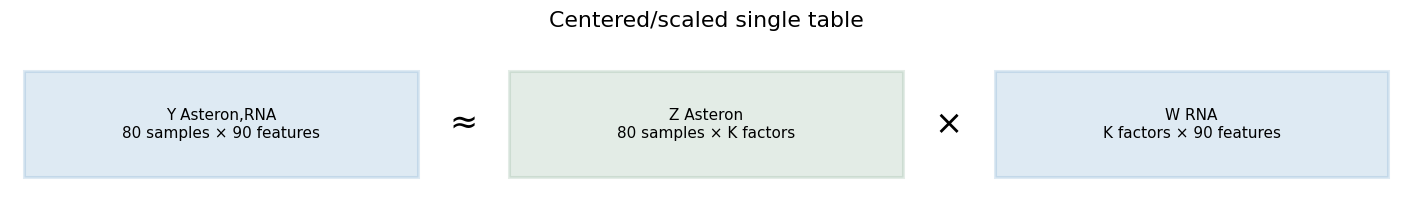

In [3]:
rna = data['Asteron']['RNA']
x = standardized(rna)
print(rna.shape, 'max absolute feature mean:', np.abs(x.mean(0)).max())
assert np.allclose(x.mean(0), 0)
display(rna.obs.head())
schematic('single')

## Fit geometric axes to Asteron RNA

We now fit **six PCA components to the centred/scaled 80 × 90 RNA table**:

$$\widetilde Y_{80\times90}\approx Z_{80\times6}W_{6\times90}.$$

`PCA(...).fit(x)` estimates orthonormal feature directions that minimise rank-six squared reconstruction error. `pca.transform(x)` projects each inhabitant onto those directions, giving `pcs` with 80 rows and six score columns. `pca.components_.T` gives `loadings` with 90 feature rows and six component columns. The transpose converts the mathematical weights orientation into a convenient feature × component table.

`score_plot` draws the **first two supplied score columns** and colours inhabitants by the supplied annotation. Disease colours are added after fitting. `weights_plot` selects the 18 features with the largest absolute weight in the supplied columns and displays their signed weights. Here we supply only PC1 and PC2, so this is a selected-feature view of those two components, not all genes or all six PCs.

Components are ordered by explained variance; their signs are arbitrary. **Predict:** if we reverse both a score column and its loading row, will their reconstructed contribution change?

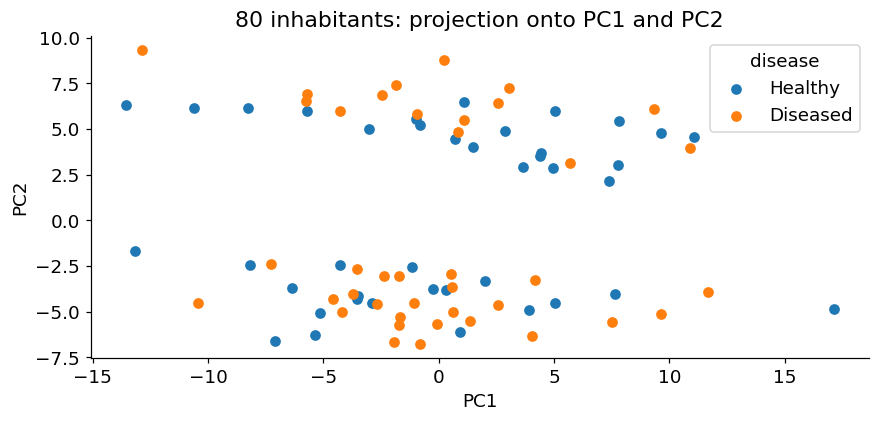

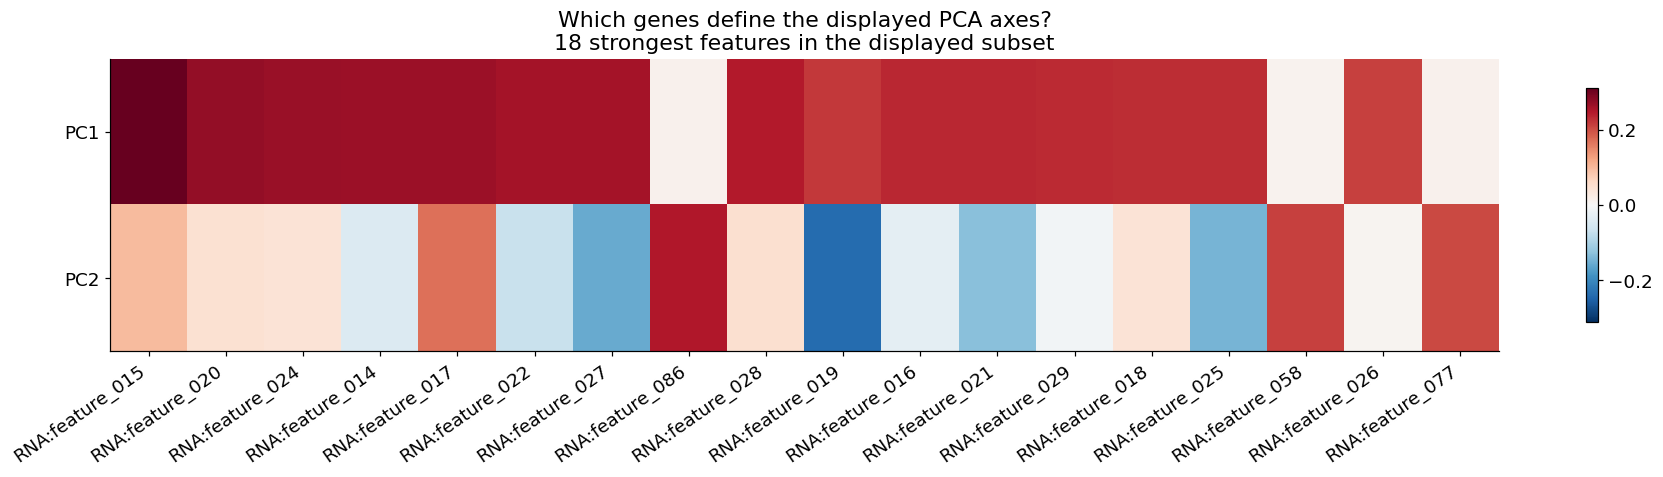

In [4]:
pca = PCA(n_components=6, svd_solver='full').fit(x)
pcs = pd.DataFrame(pca.transform(x), index=rna.obs_names,
                   columns=[f'PC{i+1}' for i in range(6)])
loadings = pd.DataFrame(pca.components_.T, index=rna.var_names, columns=pcs.columns)

score_plot(pcs, rna.obs, color='disease', title='80 inhabitants: projection onto PC1 and PC2')
weights_plot(loadings.iloc[:, :2], 'Which genes define the displayed PCA axes?')

### Ask whether the leading PCA axes are disease-related

Using the **PCA already fitted to Asteron RNA**, we now compare each component's variance fraction with its disease association. `disease_association(pcs, rna.obs)` aligns inhabitants by identifier, encodes diseased versus healthy as 1 versus 0, and returns the absolute Pearson correlation for each score column. This is a descriptive association, not a hypothesis test or a fitting target. A component can explain substantial RNA variance while showing little disease association.

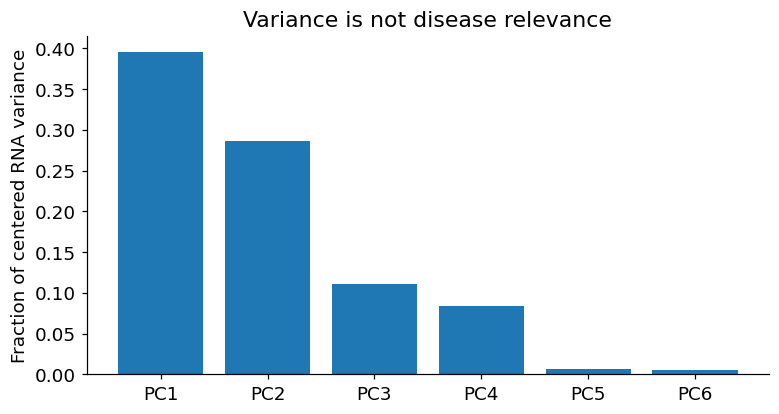

,variance_fraction,abs_disease_correlation
PC1,0.395820,0.022070
PC2,0.285628,0.097001
PC3,0.110263,0.118604
PC4,0.084059,0.814232
PC5,0.005946,0.089473
PC6,0.005507,0.037528


In [5]:
fig, ax = plt.subplots()
ax.bar(pcs.columns, pca.explained_variance_ratio_)
ax.set(ylabel='Fraction of centered RNA variance', title='Variance is not disease relevance')
plt.show()
display(pd.DataFrame({'variance_fraction': pca.explained_variance_ratio_,
                     'abs_disease_correlation': disease_association(pcs, rna.obs)}, index=pcs.columns))

## Use the fitted PCA to reconstruct the measured RNA

We are still analysing the **same six-component Asteron RNA PCA**; the next cell does not refit it. We first retain only PC1 and PC2 and multiply their scores by their loading rows to predict an 80 × 90 table.

`reconstruction_plot(x, estimate, ...)` places observations, this supplied prediction and `x - estimate` side by side with one shared colour scale. It only plots arrays; the matrix multiplication above it makes the prediction. The following loop repeats that calculation with one through six retained PCs and plots training mean squared error.

**Predict:** how much structure will remain after two PCs? Does decreasing reconstruction error establish that we have recovered disease biology?

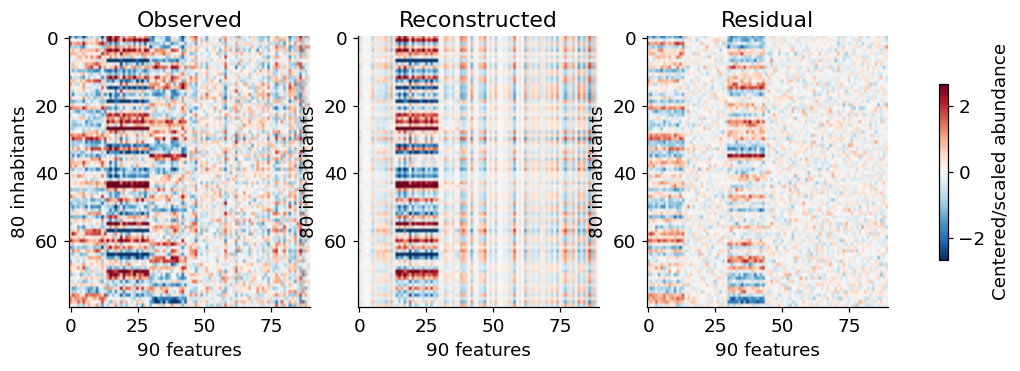

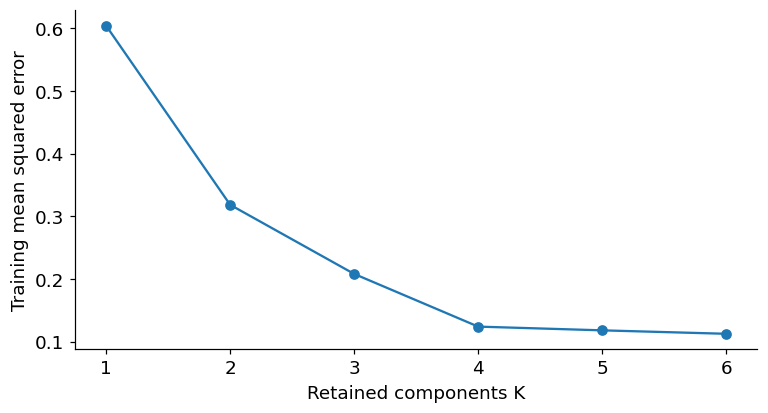

In [6]:
estimate = pcs.iloc[:, :2].to_numpy() @ pca.components_[:2]
reconstruction_plot(x, estimate, '')
errors = [np.mean((x-pcs.iloc[:, :k].to_numpy() @ pca.components_[:k])**2) for k in range(1, 7)]
plt.plot(range(1, 7), errors, 'o-'); plt.xlabel('Retained components K')
plt.ylabel('Training mean squared error'); plt.show()

## From reconstruction to R²: how much error did we remove?
**Predict:** suppose we do not know an inhabitant's factor scores. Our simplest prediction is the average abundance of each gene. How much better can a reconstruction do?

### Start with one measurement
Our code calls the centered/scaled RNA table `x`. Write it as $X$, with **80 rows (inhabitants) and 90 columns (genes)**. Each gene's mean is zero after centering; dividing the whole table by one RMS scalar does not change that.

| Symbol | Meaning | Concrete interpretation |
|---|---|---|
| $n$ | Inhabitant index, 1 to 80 | Which row? |
| $d$ | Gene index, 1 to 90 | Which column? |
| $x_{nd}$ | Observed centered/scaled abundance | The actual value in one table entry |
| $\hat{x}_{nd}$ | Reconstructed abundance | The model's prediction for that same entry |
| $x_{nd}-\hat{x}_{nd}$ | Residual | How far the prediction misses the observation |

For example, if an observed entry is **2** and the reconstruction predicts **1.5**, the residual is **0.5**. Its squared error is $0.5^2=0.25$. The mean-only prediction is **0** in these coordinates, so its squared error for the same entry is $2^2=4$.

Squaring makes positive and negative misses contribute positively: they cannot cancel. It also gives larger misses more weight. The heatmaps below show the entries that we compare; R² summarizes their squared errors.

### Add up the error for two competing predictions
**SST: how much error would the mean-only baseline make?**

$$\mathrm{SST}=\sum_{n=1}^{80}\sum_{d=1}^{90}(x_{nd}-0)^2.$$

The two summation signs mean: visit every inhabitant and every gene, square that entry's distance from its gene mean, then add all **7,200 values**. SST stands for *total sum of squares*. It is the reference error before using any factors. We keep this denominator fixed when comparing one PC with all six PCs.

**SSE: how much error does the reconstruction still make?**

$$\mathrm{SSE}(\widehat X)=\sum_{n=1}^{80}\sum_{d=1}^{90}(x_{nd}-\hat{x}_{nd})^2.$$

SSE stands for *sum of squared errors*. Here we replace the baseline prediction of zero with the reconstructed value for each entry. A better reconstruction leaves smaller residuals and therefore a smaller SSE. The hat on $\widehat X$ means “reconstructed table”; it has the same 80 × 90 dimensions as $X$.

### Turn the remaining error into a fraction removed

$$R^2=1-\underbrace{\frac{\mathrm{SSE}}{\mathrm{SST}}}_{\text{fraction of baseline squared error still remaining}}.$$

The division makes a unitless comparison. Subtracting from **1** changes “fraction remaining” into **“fraction removed by the reconstruction.”**

For an illustrative table with SST = 100 and SSE = 30, $R^2=1-30/100=0.70$: the reconstruction removes **70% of the mean-only squared error**, leaving 30%. These are example numbers; we calculate our RNA values below.

| Reconstruction | Remaining error | R² |
|---|---|---|
| Predict gene means only | SSE = SST | 0 |
| Remove 70% of baseline error | SSE = 0.30 × SST | 0.70 |
| Match every observed entry | SSE = 0 | 1 |
| Perform worse than gene means | SSE > SST | Negative before any API clipping |

We sum errors across the table, rather than averaging gene-wise R² values. Genes with greater variation therefore contribute more under our block scaling. R² = 0.70 does **not** mean 70% of genes are correct, nor that 70% of variation is disease-related.

### One factor: where does each reconstructed value come from?
Choose a component $k$, such as PC2. A **score** tells us where an inhabitant lies on this axis; a **weight** tells us how a gene varies along it. Multiplying them gives that component's contribution to one measurement:

$$\hat{x}^{[k]}_{nd}=z_{nk}\,w_{kd}.$$

- $k$ selects one fitted component; it is not an inhabitant or a gene.
- $z_{nk}$ is inhabitant $n$'s score on component $k$, taken from `pcs`.
- $w_{kd}$ is gene $d$'s weight on that component, taken from `loadings`.
- $\hat{x}^{[k]}_{nd}$ is the value predicted **using only this component**. For a score of 2 and a weight of −0.4, the predicted contribution is −0.8 in centered/scaled units.

Do this for every inhabitant and gene at once using an **outer product**: a column of 80 scores times a row of 90 weights makes an 80 × 90 table.

$$\widehat X^{[k]}_{80\times90}=Z_{:,k\;(80\times1)}W_{k,:\;(1\times90)}.$$

Compare this single-factor table against the **entire observed table** to obtain its SSE and R². Variation captured by other components remains in the residual. This is a **factor-alone** R²; it does not measure the loss from removing this factor from the full model.

Change `component` below to inspect another PC. The diagram shows how the two vectors produce the predicted table.

In [7]:
component = 'PC2'  # Any fitted PC1 ... PC6
z_k = pcs[[component]].to_numpy()                 # 80 × 1 scores
w_k = loadings[[component]].to_numpy().T          # 1 × 90 weights
factor_reconstruction = z_k @ w_k                 # 80 × 90 outer product

### Look at the two vectors before their product

These panels display the score column and weight row we just selected from the **existing PCA**, followed by their outer product. `imshow` shows their entries; no new model is fitted. Each panel has its own colour limits, so compare patterns rather than colour intensity across panels. The product has the same inhabitant × gene dimensions as the measurements.

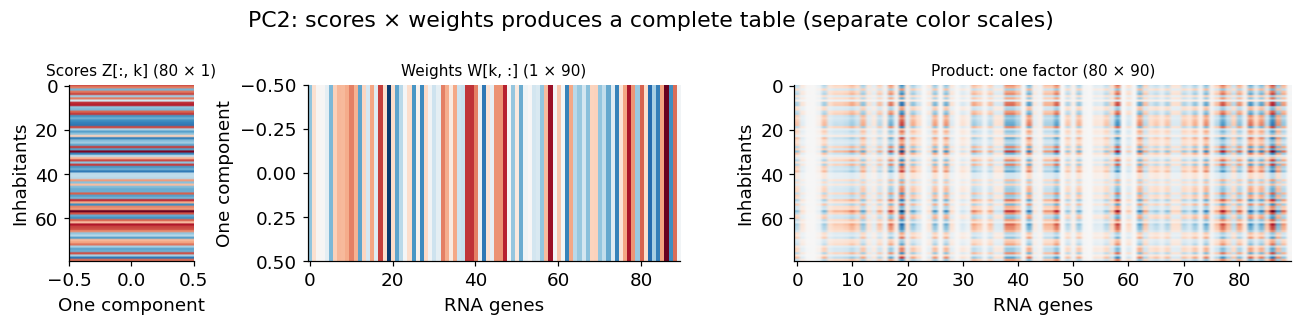

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), gridspec_kw={'width_ratios': [1, 3, 4]})
for ax, matrix, label in zip(axes, [z_k, w_k, factor_reconstruction],
                           ['Scores Z[:, k] (80 × 1)', 'Weights W[k, :] (1 × 90)',
                            'Product: one factor (80 × 90)']):
    bound = max(np.abs(matrix).max(), 1e-12)
    ax.imshow(matrix, aspect='auto', cmap='RdBu_r', vmin=-bound, vmax=bound)
    ax.set_title(label, fontsize=10)
axes[0].set(xlabel='One component', ylabel='Inhabitants')
axes[1].set(xlabel='RNA genes', ylabel='One component')
axes[2].set(xlabel='RNA genes', ylabel='Inhabitants')
fig.suptitle(f'{component}: scores × weights produces a complete table (separate color scales)')
plt.tight_layout(); plt.show()

### Whole model: add each factor's predicted contribution
One component supplies one contribution per entry. The full reconstruction adds the contributions from **all six fitted PCs**:

$$\hat{x}^{\mathrm{all}}_{nd}=\underbrace{z_{n1}w_{1d}}_{\text{PC1 contribution}}+
\underbrace{z_{n2}w_{2d}}_{\text{PC2 contribution}}+\cdots+
\underbrace{z_{n6}w_{6d}}_{\text{PC6 contribution}}.$$

For one measurement, contributions of 1.2 and 0.3 would combine to predict 1.5; we then compare that **sum** with the observation. We do not square each factor's residual and then add those errors.

Across the complete table, this addition is matrix multiplication:

$$\widehat X^{\mathrm{all}}_{80\times90}=Z_{80\times6}W_{6\times90}.$$

Use the same R² recipe, now with the summed prediction:

$$R^2_{\mathrm{all}}=1-\frac{\sum_{n=1}^{80}\sum_{d=1}^{90}(x_{nd}-\hat{x}^{\mathrm{all}}_{nd})^2}{\mathrm{SST}}.$$

Only the **reconstruction in the numerator changes**. The observed data and mean-only denominator remain the same. “Whole model” here means all six retained PCs, not all possible PCs or the true simulated processes.

**Predict:** will PC2 alone or the whole six-PC model leave more residual structure? Read the next panels from left to right: **observations → reconstruction → residuals**. The numerical table then squares and sums those residuals and divides by the common baseline error.

### Reassemble all six retained components

`pcs.to_numpy() @ pca.components_` adds the contributions of all six fitted PCs to reconstruct the same Asteron RNA table. We keep the earlier single-component reconstruction for comparison. These are two predictions from one fitted PCA, not two separately trained models.

In [9]:
whole_reconstruction = pcs.to_numpy() @ pca.components_

### Compare one component with the whole fitted PCA

We pass each prediction to `reconstruction_plot`, which subtracts it from the same observed `x`. Within each call the three panels share a colour scale set from `x`. Read the residuals as variation left unexplained by that particular prediction; the six-component prediction can use contributions that PC2 alone omits.

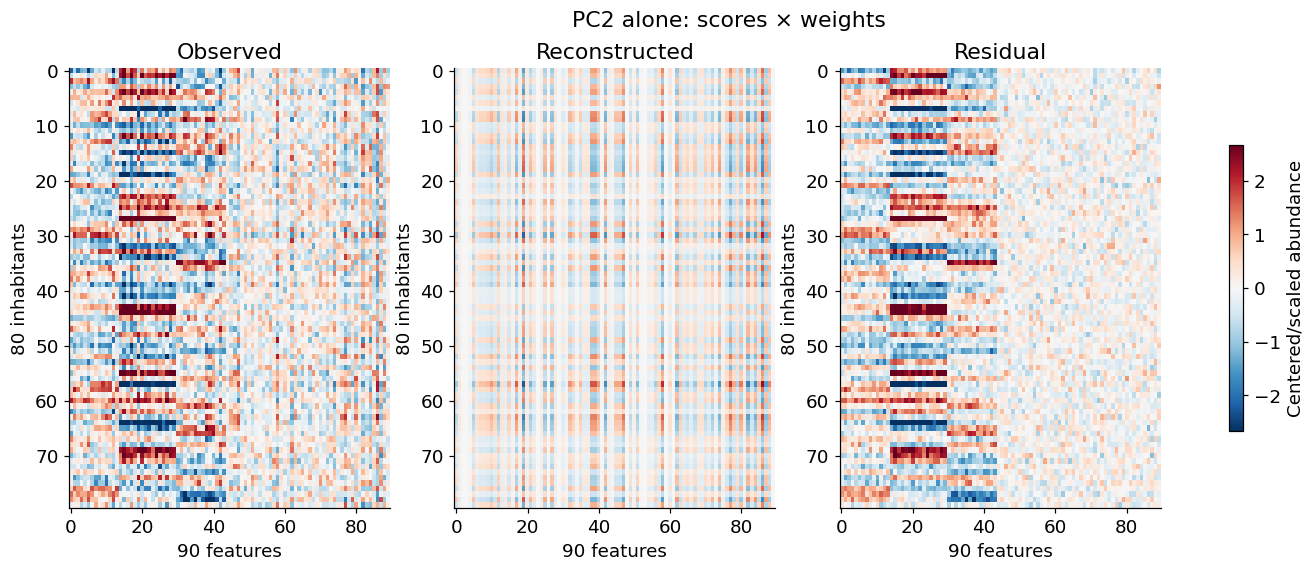

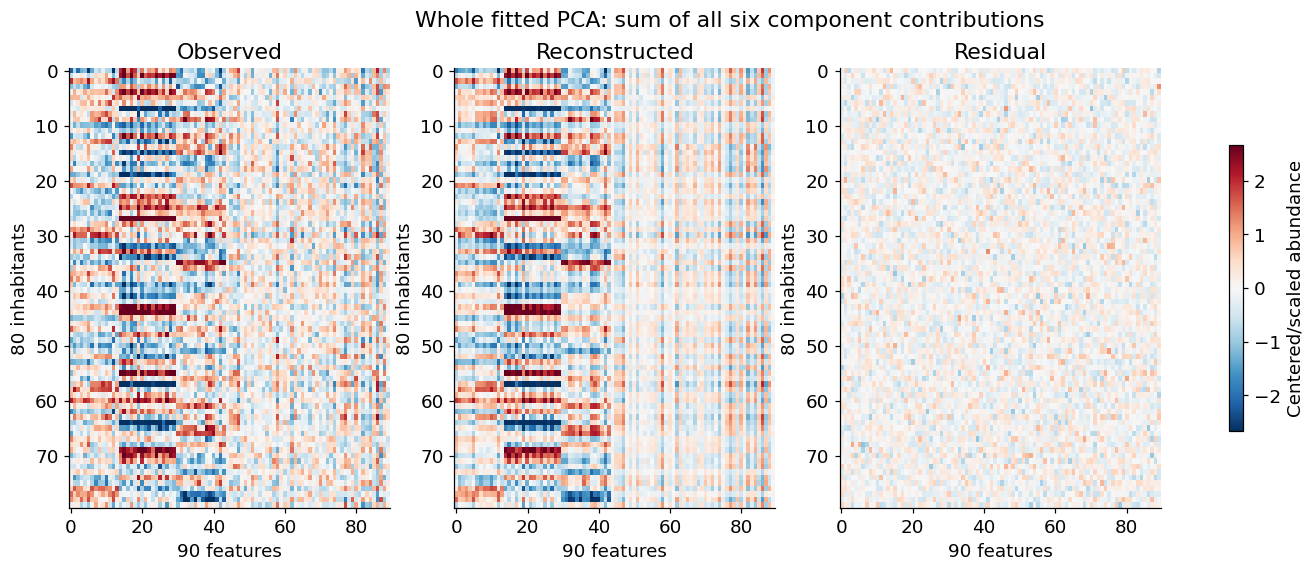

In [10]:
# Change size of the plots below
reconstruction_plot(x, factor_reconstruction, f'{component} alone: scores × weights', figsize=(16, 5.2))
reconstruction_plot(x, whole_reconstruction, 'Whole fitted PCA: sum of all six component contributions', figsize=(16, 5.2))

### Calculate the errors shown in the panels

We now compute the numbers directly, using the **same PCA and observed table**. `sst` is the squared error of predicting feature means, which are zero in `x`. Each row's `SSE` sums the squared residuals of one supplied prediction. The final two columns show the fraction of baseline error left and removed. No helper computes this table, so we can trace every quantity back to the plotted arrays.

In [11]:
sst = np.sum(x**2)  # Mean-only baseline error; x has zero feature means
reconstructions = {'Mean only (baseline)': np.zeros_like(x),
                   f'{component} alone': factor_reconstruction,
                   'Whole model (6 PCs)': whole_reconstruction}
r2_summary = pd.DataFrame({
    label: {'SST (same baseline)': sst, 'SSE': np.sum((x - prediction)**2)}
    for label, prediction in reconstructions.items()
}).T
r2_summary['Residual fraction SSE/SST'] = r2_summary['SSE'] / sst
r2_summary['R² = 1 − SSE/SST'] = 1 - r2_summary['Residual fraction SSE/SST']
display(r2_summary.round(4))

,SST (same baseline),SSE,Residual fraction SSE/SST,R² = 1 − SSE/SST
Mean only (baseline),7200.0,7200.0000,1.0000,0.0000
PC2 alone,7200.0,5143.4779,0.7144,0.2856
Whole model (6 PCs),7200.0,811.9952,0.1128,0.8872


### Check the connection to PCA's explained variance
**Predict:** will R² from each PC's reconstruction match the variance fractions plotted earlier? Will adding the six factor-alone values give whole-model R²?

For centered, orthogonal PCA these equalities hold. The next plot contrasts a component **alone** with the reconstruction obtained by retaining **PC1 through PCk**.

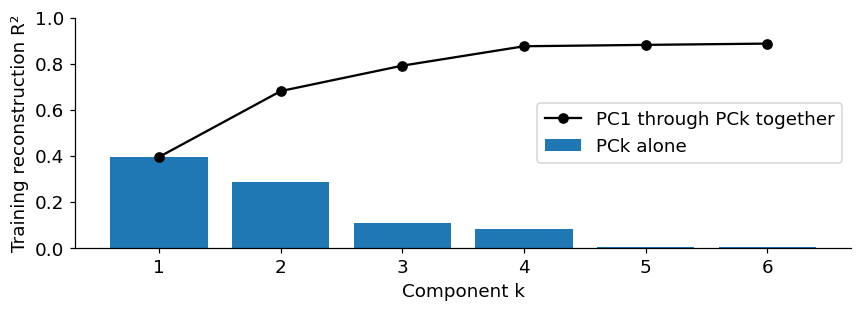

In [12]:
factor_r2 = np.array([
    1 - np.sum((x - np.outer(pcs[name], loadings[name]))**2) / sst
    for name in pcs.columns
])
cumulative_r2 = np.array([
    1 - np.sum((x - pcs.iloc[:, :k].to_numpy() @ pca.components_[:k])**2) / sst
    for k in range(1, 7)
])
fig, ax = plt.subplots(figsize=(8, 3))
positions = np.arange(1, 7)
ax.bar(positions, factor_r2, label='PCk alone')
ax.plot(positions, cumulative_r2, 'o-', color='black', label='PC1 through PCk together')
ax.set(xticks=positions, xlabel='Component k', ylabel='Training reconstruction R²', ylim=(0, 1))
ax.legend(); plt.tight_layout(); plt.show()
assert np.allclose(factor_r2, pca.explained_variance_ratio_)
assert np.allclose(cumulative_r2, np.cumsum(factor_r2))
assert np.isclose(factor_r2.sum(), r2_summary.loc['Whole model (6 PCs)', 'R² = 1 − SSE/SST'])

### Carry the reconstruction idea into MOFA-FLEX
For the **Gaussian model in the next notebook**, MOFA-FLEX uses the same squared-error idea, with its fitted feature means as the baseline. Its predictions are restored to measurement units; our single block RMS scaling cancels in the SSE/SST ratio.

| Quantity | Reconstruction used | Verified course API (next notebook) |
|---|---|---|
| Factor $k$ alone | That factor's score × weight contribution | `model.get_r2()` (one factor term) |
| Whole model | Sum of all fitted factor contributions | `model.get_r2(type='total')` |

MOFA-FLEX factors need not be orthogonal. **Do not sum factor-alone R² values to obtain total R²:** contributions can overlap or cancel. Reconstruct the whole model first, then compute its residual error. Neither quantity is a score–disease correlation or the teacher-score recovery R² shown below.

The pinned API clips negative Gaussian R² to zero; the un-clipped formula above would be negative for a reconstruction worse than the mean-only baseline. For later multiview/group analyses the calculation is repeated for each view/group, using the appropriate baseline and observed entries. Other likelihoods can use different diagnostics.

**Interpret:** what does the selected component leave unexplained? Why can high whole-model R² coexist with poor disease recovery? This is training reconstruction, so it does not establish prediction on new inhabitants or biological correctness.

## How good are we at recovering the expected patterns?
We now change the question. Reconstruction R² above measures recovery of **measured RNA abundances**. The following teacher diagnostic measures recovery of **known simulated sample activities**, such as inflammation or metabolism.

The correlation heatmap compares individual PCs with individual true processes. Absolute correlations avoid sign ambiguity; they do not remove mixing or prove one-to-one recovery.

`truth_projection(pcs, teacher['scores']['Asteron'])` instead asks: **can a linear combination of all six PC score columns reproduce each true activity across inhabitants?** For each true process it:

1. Matches rows by inhabitant ID and centers the learned scores and true activities.
2. Fits least-squares coefficients that combine the learned score columns to predict that true activity.
3. Reports $1-\text{remaining squared activity error}/\text{total squared true activity variation}$.

For example, inflammation could be spread across PC2 and PC4. Neither PC alone need correlate perfectly with inflammation, while their fitted combination may recover it well. This diagnostic therefore evaluates the **space spanned by the learned scores**, rather than requiring a one-to-one factor match. Sign flips, permutations and invertible rotations of that space do not change the result.

A value near 1 means the learned score space can reproduce that true activity on these inhabitants; near 0 means it provides little linear recovery. This uses simulation truth **only after unsupervised fitting**, to evaluate the result. It is a training diagnostic, not validation on new samples; extra components can improve it by fitting chance structure. It does not test recovery of the feature weights, and it is not MOFA-FLEX's data-reconstruction R².

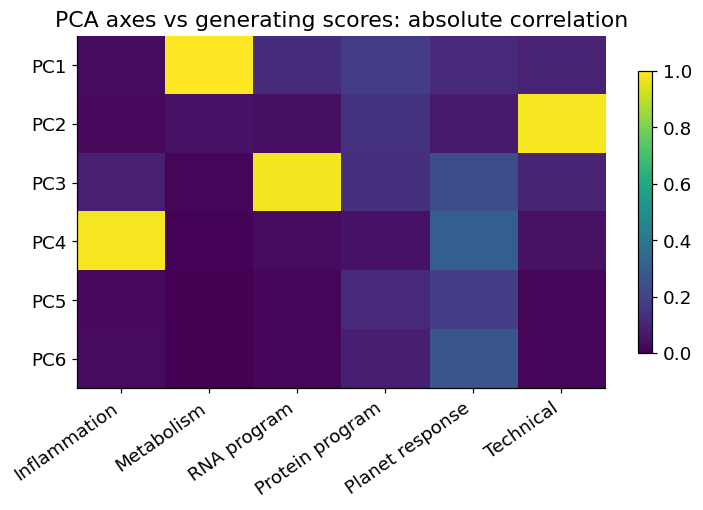

Inflammation       0.981916
Metabolism         0.996516
RNA program        0.987261
Protein program    0.096669
Planet response    0.265804
Technical          0.996723
Name: Score-subspace training R², dtype: float64

In [13]:
teacher = load_truth()
heatmap(crosscorr(pcs, teacher['scores']['Asteron']).abs(),
        'PCA axes vs generating scores: absolute correlation', vmin=0, vmax=1)
display(truth_projection(pcs, teacher['scores']['Asteron']).rename('Score-subspace training R²'))

**Learned:** sample coordinates and gene loadings reconstruct variation; PC1 can follow dominant metabolism rather than disease. **Ambiguous:** true processes need not coincide with individual orthogonal PCs, and RNA cannot observe a process with zero RNA weights. A two-axis map shows only a projection, not all sample relationships.

 **Next:** PCA supplies a geometric solution. What changes when residual noise and parameter assumptions become explicit probability distributions?
